In [1]:
import os
import cv2
import torch
import random
import numpy as np

import matplotlib.pyplot as plt

from PIL import Image

from torchvision import transforms

In [2]:
DEVICE = torch.device(

    "cuda"

    if torch.cuda.is_available()

    else "cpu"

)

print(DEVICE)

cuda


In [3]:
DATASET_PATH = r"D:\Multicrop Disease Dataset"

In [4]:
image_extensions = (

    ".jpg",

    ".jpeg",

    ".png",

    ".bmp"

)

all_images = []

for root, dirs, files in os.walk(DATASET_PATH):

    for file in files:

        if file.lower().endswith(

            image_extensions

        ):

            all_images.append(

                os.path.join(

                    root,

                    file

                )

            )

print(

    "Images:",

    len(all_images)

)

Images: 21875


In [6]:
import os
import cv2
import torch
import random
import numpy as np

import torch.nn as nn

import matplotlib.pyplot as plt

from PIL import Image

from torchvision import transforms

In [7]:
print(torch.__version__)
print(nn)

2.5.1+cu121
<module 'torch.nn' from 'C:\\Users\\admin\\anaconda3\\envs\\research\\lib\\site-packages\\torch\\nn\\__init__.py'>


In [8]:
class SpatialAttention(nn.Module):

    def __init__(self):

        super().__init__()

        self.conv = nn.Conv2d(

            2,
            1,
            kernel_size=7,
            padding=3

        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_out = torch.mean(
            x,
            dim=1,
            keepdim=True
        )

        max_out, _ = torch.max(
            x,
            dim=1,
            keepdim=True
        )

        x_cat = torch.cat(
            [avg_out, max_out],
            dim=1
        )

        attention = self.sigmoid(
            self.conv(x_cat)
        )

        return attention

In [9]:
class ResidualAttentionBlock(nn.Module):

    def __init__(
        self,
        channels
    ):

        super().__init__()

        self.conv1 = nn.Conv2d(

            channels,
            channels,
            3,
            padding=1

        )

        self.relu = nn.ReLU()

        self.conv2 = nn.Conv2d(

            channels,
            channels,
            3,
            padding=1

        )

        self.attention = SpatialAttention()

    def forward(self, x):

        residual = x

        out = self.conv1(x)

        out = self.relu(out)

        out = self.conv2(out)

        A = self.attention(out)

        out = out * A

        return residual + out

In [10]:
block = ResidualAttentionBlock(
    64
)

dummy = torch.randn(
    1,
    64,
    256,
    256
)

output = block(dummy)

print(output.shape)

torch.Size([1, 64, 256, 256])


In [11]:
attention = SpatialAttention()

dummy = torch.randn(
    1,
    64,
    256,
    256
)

A = attention(dummy)

print(A.shape)

torch.Size([1, 1, 256, 256])


In [12]:
class EncoderBlock(nn.Module):

    def __init__(self, in_channels, out_channels):

        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                3,
                padding=1
            ),

            nn.BatchNorm2d(
                out_channels
            ),

            nn.ReLU(),

            ResidualAttentionBlock(
                out_channels
            )

        )

        self.pool = nn.MaxPool2d(2)

    def forward(self, x):

        features = self.block(x)

        pooled = self.pool(features)

        return features, pooled

In [13]:
class DecoderBlock(nn.Module):

    def __init__(self, in_channels, skip_channels, out_channels):

        super().__init__()

        self.up = nn.ConvTranspose2d(

            in_channels,
            out_channels,
            kernel_size=2,
            stride=2

        )

        self.conv = nn.Sequential(

            nn.Conv2d(

                out_channels + skip_channels,
                out_channels,
                3,
                padding=1

            ),

            nn.BatchNorm2d(
                out_channels
            ),

            nn.ReLU(),

            ResidualAttentionBlock(
                out_channels
            )

        )

    def forward(self, x, skip):

        x = self.up(x)

        x = torch.cat(
            [x, skip],
            dim=1
        )

        x = self.conv(x)

        return x

In [14]:
class MultiScaleHead(nn.Module):

    def __init__(self, channels):

        super().__init__()

        self.head = nn.Conv2d(
            channels,
            3,
            1
        )

    def forward(self, x):

        return torch.sigmoid(
            self.head(x)
        )

In [15]:
class ARTEN(nn.Module):

    def __init__(self):

        super().__init__()

        self.enc1 = EncoderBlock(
            3,
            64
        )

        self.enc2 = EncoderBlock(
            64,
            128
        )

        self.enc3 = EncoderBlock(
            128,
            256
        )

        self.bottleneck = nn.Sequential(

            nn.Conv2d(
                256,
                512,
                3,
                padding=1
            ),

            nn.ReLU(),

            ResidualAttentionBlock(
                512
            )

        )

        self.dec3 = DecoderBlock(
            512,
            256,
            256
        )

        self.dec2 = DecoderBlock(
            256,
            128,
            128
        )

        self.dec1 = DecoderBlock(
            128,
            64,
            64
        )

        self.final = nn.Conv2d(
            64,
            3,
            1
        )

        self.ms1 = MultiScaleHead(256)
        self.ms2 = MultiScaleHead(128)
        self.ms3 = MultiScaleHead(64)

    def forward(self, x):

        s1, p1 = self.enc1(x)

        s2, p2 = self.enc2(p1)

        s3, p3 = self.enc3(p2)

        bottleneck = self.bottleneck(p3)

        d3 = self.dec3(
            bottleneck,
            s3
        )

        d2 = self.dec2(
            d3,
            s2
        )

        d1 = self.dec1(
            d2,
            s1
        )

        out = torch.sigmoid(
            self.final(d1)
        )

        ms_out1 = self.ms1(d3)

        ms_out2 = self.ms2(d2)

        ms_out3 = self.ms3(d1)

        return (
            out,
            ms_out1,
            ms_out2,
            ms_out3
        )

In [21]:
model = ARTEN().to(
    DEVICE
)

print(model)

ARTEN(
  (enc1): EncoderBlock(
    (block): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): ResidualAttentionBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (relu): ReLU()
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (attention): SpatialAttention(
          (conv): Conv2d(2, 1, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
          (sigmoid): Sigmoid()
        )
      )
    )
    (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (enc2): EncoderBlock(
    (block): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): ResidualAttentionBlo

In [22]:
import os

MODEL_PATH = r"D:\ARTEN_Project\ARTEN_Model.pth"

print("Exists:", os.path.exists(MODEL_PATH))
print("Current Directory:", os.getcwd())

Exists: False
Current Directory: C:\Users\admin


In [23]:
MODEL_PATH = r"C:\Users\admin\ARTEN_Model.pth"

In [24]:
import os

MODEL_PATH = r"C:\Users\admin\ARTEN_Model.pth"

print(os.path.exists(MODEL_PATH))

True


In [25]:
model.load_state_dict(
    torch.load(
        MODEL_PATH,
        map_location=DEVICE
    )
)

model.eval()

print("ARTEN Loaded Successfully")

ARTEN Loaded Successfully


C:\Users\admin\AppData\Local\Temp\ipykernel_24104\1565313727.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(


In [26]:
transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((256,256)),
    transforms.ToTensor()
])

In [27]:
sample_path = random.choice(all_images)

print(sample_path)

D:\Multicrop Disease Dataset\train\images\Mosaic-Virus-347-_jpg.rf.15960bcc13fcd1c59b2d434a56476abf.jpg


In [32]:
img = cv2.imread(
    sample_path
)

img_rgb = cv2.cvtColor(
    img,
    cv2.COLOR_BGR2RGB
)

tensor = transform(
    img_rgb
)

tensor = tensor.unsqueeze(0)

tensor = tensor.to(
    DEVICE
)

with torch.no_grad():

    pred, _, _, _ = model(
        tensor
    )

pred = pred.squeeze()

pred = pred.cpu().numpy()

pred = np.transpose(
    pred,
    (1,2,0)
)

pred = (
    pred * 255
).astype(
    np.uint8
)

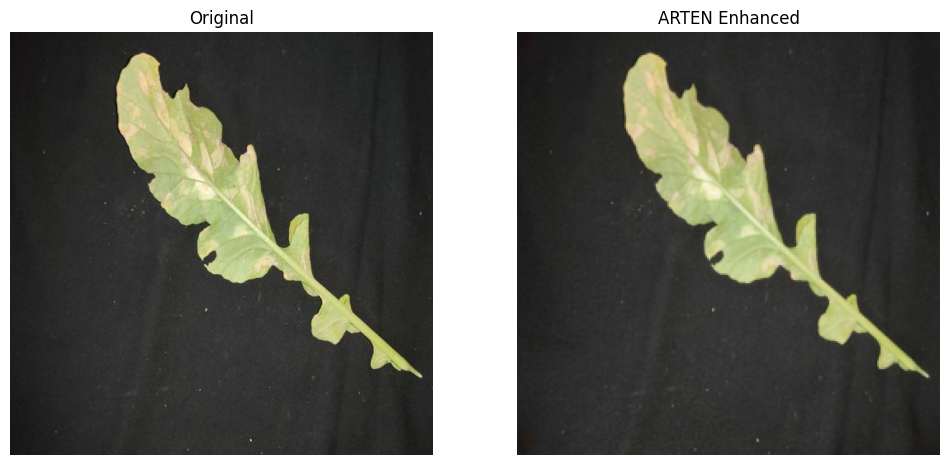

In [33]:
plt.figure(
    figsize=(12,6)
)

plt.subplot(1,2,1)

plt.imshow(
    img_rgb
)

plt.title(
    "Original"
)

plt.axis("off")

plt.subplot(1,2,2)

plt.imshow(
    pred
)

plt.title(
    "ARTEN Enhanced"
)

plt.axis("off")

plt.show()

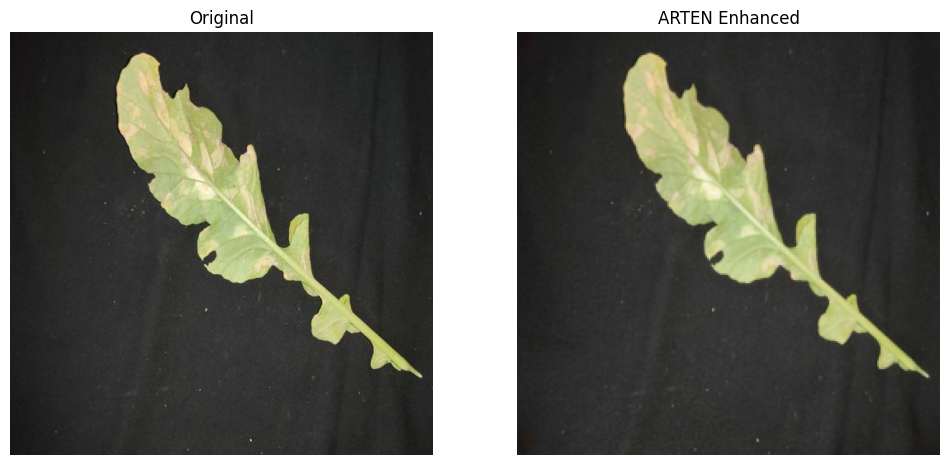

Saved


In [34]:
plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.imshow(img_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(pred)
plt.title("ARTEN Enhanced")
plt.axis("off")

plt.savefig(
    "ARTEN_Comparison.png",
    bbox_inches="tight",
    dpi=300
)

plt.show()

print("Saved")

In [35]:
def laplacian_variance(image):

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2GRAY
    )

    return cv2.Laplacian(
        gray,
        cv2.CV_64F
    ).var()

In [36]:
orig_score = laplacian_variance(
    img_rgb
)

enh_score = laplacian_variance(
    pred
)

print(
    "Original Clarity:",
    orig_score
)

print(
    "Enhanced Clarity:",
    enh_score
)

improvement = (
    (enh_score - orig_score)
    /
    orig_score
) * 100

print(
    "Improvement (%):",
    improvement
)

Original Clarity: 119.19483351037499
Enhanced Clarity: 250.7041601985693
Improvement (%): 110.33139844668472


In [37]:
from skimage.metrics import structural_similarity
from skimage.metrics import peak_signal_noise_ratio

In [39]:
print("Original Shape:", img_rgb.shape)
print("Enhanced Shape:", pred.shape)

Original Shape: (640, 640, 3)
Enhanced Shape: (256, 256, 3)


In [40]:
img_resized = cv2.resize(
    img_rgb,
    (256,256)
)

print(img_resized.shape)
print(pred.shape)

(256, 256, 3)
(256, 256, 3)


In [41]:
psnr = peak_signal_noise_ratio(
    img_resized,
    pred,
    data_range=255
)

ssim = structural_similarity(
    img_resized,
    pred,
    channel_axis=2,
    data_range=255
)

print("PSNR :", psnr)
print("SSIM :", ssim)

PSNR : 37.98424555463045
SSIM : 0.976836692372098


In [42]:
ENHANCED_ROOT = r"D:\ARTEN_Enhanced_Dataset"

os.makedirs(
    ENHANCED_ROOT,
    exist_ok=True
)

print("Output Folder Created")

Output Folder Created


In [43]:
def enhance_image(image_path):

    img = cv2.imread(image_path)

    img_rgb = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2RGB
    )

    tensor = transform(img_rgb)

    tensor = tensor.unsqueeze(0)

    tensor = tensor.to(DEVICE)

    with torch.no_grad():

        pred, _, _, _ = model(tensor)

    pred = pred.squeeze().cpu().numpy()

    pred = np.transpose(pred, (1,2,0))

    pred = (pred * 255).astype(np.uint8)

    return pred

In [44]:
from tqdm import tqdm

test_images = all_images[:20]

for path in tqdm(test_images):

    enhanced = enhance_image(path)

print("20 Images Tested Successfully")

100%|██████████████████████████████████████████████████████████████████████████████████| 20/20 [00:00<00:00, 41.63it/s]

20 Images Tested Successfully


In [45]:
from tqdm import tqdm

log_data = []

for image_path in tqdm(all_images):

    relative_path = os.path.relpath(
        image_path,
        DATASET_PATH
    )

    save_path = os.path.join(
        ENHANCED_ROOT,
        relative_path
    )

    os.makedirs(
        os.path.dirname(save_path),
        exist_ok=True
    )

    enhanced = enhance_image(
        image_path
    )

    enhanced_bgr = cv2.cvtColor(
        enhanced,
        cv2.COLOR_RGB2BGR
    )

    cv2.imwrite(
        save_path,
        enhanced_bgr
    )

    log_data.append(
        [
            image_path,
            save_path
        ]
    )

print("Dataset Enhancement Completed")

100%|████████████████████████████████████████████████████████████████████████████| 21875/21875 [04:53<00:00, 74.53it/s]

Dataset Enhancement Completed


In [46]:
import pandas as pd

log_df = pd.DataFrame(

    log_data,

    columns=[
        "Original_Image",
        "Enhanced_Image"
    ]

)

log_df.to_csv(

    "enhancement_log.csv",

    index=False

)

print("Log Saved")

Log Saved


In [47]:
enhanced_images = []

for root, dirs, files in os.walk(
    ENHANCED_ROOT
):

    for file in files:

        if file.lower().endswith(
            (
                '.jpg',
                '.jpeg',
                '.png',
                '.bmp'
            )
        ):

            enhanced_images.append(
                os.path.join(
                    root,
                    file
                )
            )

print(
    "Enhanced Images:",
    len(enhanced_images)
)

Enhanced Images: 21875


In [48]:
import pandas as pd

metadata = []

for path in enhanced_images:

    metadata.append([
        path
    ])

metadata_df = pd.DataFrame(
    metadata,
    columns=["Image_Path"]
)

metadata_df.to_csv(
    "metadata.csv",
    index=False
)

print("Metadata Saved")

Metadata Saved


In [49]:
metadata_df.head()

,Image_Path
0,D:\ARTEN_Enhanced_Dataset\test\images\Anthracn...
1,D:\ARTEN_Enhanced_Dataset\test\images\Anthracn...
2,D:\ARTEN_Enhanced_Dataset\test\images\Anthracn...
3,D:\ARTEN_Enhanced_Dataset\test\images\Anthracn...
4,D:\ARTEN_Enhanced_Dataset\test\images\Anthracn...


In [50]:
import shutil

shutil.make_archive(
    "ARTEN_Enhanced_Dataset",
    "zip",
    ENHANCED_ROOT
)

print("ZIP Created")

ZIP Created


In [51]:
import os

print(
    os.path.exists(
        "ARTEN_Enhanced_Dataset.zip"
    )
)

print(
    os.path.getsize(
        "ARTEN_Enhanced_Dataset.zip"
    ) / (1024**3),
    "GB"
)

True
0.4715682528913021 GB


In [52]:
import cv2
import random

sample_original = random.choice(all_images)

relative_path = os.path.relpath(
    sample_original,
    DATASET_PATH
)

sample_enhanced = os.path.join(
    ENHANCED_ROOT,
    relative_path
)

orig = cv2.imread(sample_original)
enh = cv2.imread(sample_enhanced)

print("Original Shape :", orig.shape)
print("Enhanced Shape :", enh.shape)

Original Shape : (640, 640, 3)
Enhanced Shape : (256, 256, 3)


In [53]:
ENHANCED_ROOT = r"D:\ARTEN_Enhanced_Dataset_640"

os.makedirs(
    ENHANCED_ROOT,
    exist_ok=True
)

print("Output Folder Created")

Output Folder Created


In [54]:
def enhance_image(image_path):

    img = cv2.imread(image_path)

    img_rgb = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2RGB
    )

    # Store original size
    orig_h, orig_w = img_rgb.shape[:2]

    # ARTEN input
    tensor = transform(
        img_rgb
    )

    tensor = tensor.unsqueeze(0)

    tensor = tensor.to(DEVICE)

    with torch.no_grad():

        pred, _, _, _ = model(
            tensor
        )

    pred = pred.squeeze().cpu().numpy()

    pred = np.transpose(
        pred,
        (1,2,0)
    )

    pred = (
        pred * 255
    ).astype(np.uint8)

    # Resize back to original resolution
    pred = cv2.resize(
        pred,
        (orig_w, orig_h),
        interpolation=cv2.INTER_CUBIC
    )

    return pred

In [55]:
sample_path = random.choice(all_images)

enhanced = enhance_image(sample_path)

orig = cv2.imread(sample_path)

print("Original Shape :", orig.shape)

print("Enhanced Shape :", enhanced.shape)

Original Shape : (640, 640, 3)
Enhanced Shape : (640, 640, 3)


In [56]:
from tqdm import tqdm

test_images = all_images[:20]

for path in tqdm(test_images):

    enhanced = enhance_image(path)

print("20 Images Tested Successfully")

100%|██████████████████████████████████████████████████████████████████████████████████| 20/20 [00:00<00:00, 38.22it/s]

20 Images Tested Successfully


In [57]:
from tqdm import tqdm

log_data = []

for image_path in tqdm(all_images):

    relative_path = os.path.relpath(
        image_path,
        DATASET_PATH
    )

    save_path = os.path.join(
        ENHANCED_ROOT,
        relative_path
    )

    os.makedirs(
        os.path.dirname(save_path),
        exist_ok=True
    )

    enhanced = enhance_image(
        image_path
    )

    enhanced_bgr = cv2.cvtColor(
        enhanced,
        cv2.COLOR_RGB2BGR
    )

    cv2.imwrite(
        save_path,
        enhanced_bgr
    )

    log_data.append(
        [image_path, save_path]
    )

print("640x640 Dataset Enhancement Completed")

100%|████████████████████████████████████████████████████████████████████████████| 21875/21875 [06:33<00:00, 55.64it/s]

640x640 Dataset Enhancement Completed


In [58]:
enhanced_images = []

for root, dirs, files in os.walk(
    ENHANCED_ROOT
):

    for file in files:

        if file.lower().endswith(
            ('.jpg','.jpeg','.png','.bmp')
        ):

            enhanced_images.append(
                os.path.join(root,file)
            )

print(
    "Enhanced Images:",
    len(enhanced_images)
)

Enhanced Images: 21875


In [59]:
sample_original = random.choice(all_images)

relative_path = os.path.relpath(
    sample_original,
    DATASET_PATH
)

sample_enhanced = os.path.join(
    ENHANCED_ROOT,
    relative_path
)

orig = cv2.imread(sample_original)
enh = cv2.imread(sample_enhanced)

print("Original Shape :", orig.shape)
print("Enhanced Shape :", enh.shape)

Original Shape : (640, 640, 3)
Enhanced Shape : (640, 640, 3)


In [60]:
import shutil

shutil.make_archive(
    "ARTEN_Enhanced_Dataset_640",
    "zip",
    ENHANCED_ROOT
)

print("ZIP Created")

ZIP Created


In [61]:
import os

print(
    os.path.exists(
        "ARTEN_Enhanced_Dataset_640.zip"
    )
)

print(
    os.path.getsize(
        "ARTEN_Enhanced_Dataset_640.zip"
    ) / (1024**3),
    "GB"
)

True
1.7095210431143641 GB


In [62]:
ORIGINAL_ROOT = r"D:\Multicrop Disease Dataset"

ENHANCED_ROOT = r"D:\ARTEN_Enhanced_Dataset_640"

In [63]:
original_images = []

enhanced_images = []

for root, dirs, files in os.walk(ORIGINAL_ROOT):

    for file in files:

        if file.lower().endswith(
            ('.jpg','.jpeg','.png','.bmp')
        ):

            orig_path = os.path.join(
                root,
                file
            )

            relative_path = os.path.relpath(
                orig_path,
                ORIGINAL_ROOT
            )

            enh_path = os.path.join(
                ENHANCED_ROOT,
                relative_path
            )

            if os.path.exists(enh_path):

                original_images.append(
                    orig_path
                )

                enhanced_images.append(
                    enh_path
                )

print("Pairs:", len(original_images))

Pairs: 21875


In [64]:
indices = random.sample(
    range(len(original_images)),
    1000
)

orig_sample = [
    original_images[i]
    for i in indices
]

enh_sample = [
    enhanced_images[i]
    for i in indices
]

In [65]:
def clarity_score(image):

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2GRAY
    )

    return cv2.Laplacian(
        gray,
        cv2.CV_64F
    ).var()

In [66]:
results = []

for orig_path, enh_path in tqdm(
    zip(orig_sample, enh_sample),
    total=len(orig_sample)
):

    orig = cv2.imread(orig_path)

    enh = cv2.imread(enh_path)

    orig_clarity = clarity_score(
        orig
    )

    enh_clarity = clarity_score(
        enh
    )

    psnr = peak_signal_noise_ratio(
        orig,
        enh,
        data_range=255
    )

    ssim = structural_similarity(
        orig,
        enh,
        channel_axis=2,
        data_range=255
    )

    results.append([

        orig_clarity,

        enh_clarity,

        psnr,

        ssim

    ])

100%|██████████████████████████████████████████████████████████████████████████████| 1000/1000 [02:02<00:00,  8.16it/s]


In [67]:
results_df = pd.DataFrame(

    results,

    columns=[

        "Original_Clarity",

        "Enhanced_Clarity",

        "PSNR",

        "SSIM"

    ]

)

results_df.head()

,Original_Clarity,Enhanced_Clarity,PSNR,SSIM
0,34.483030,4.511848,37.165705,0.969758
1,94.321125,11.671011,34.216267,0.942604
2,252.868282,27.427306,30.757249,0.891248
3,117.213161,13.644733,29.652433,0.883403
4,43.520644,6.436928,29.284361,0.950644


In [68]:
results_df.to_csv(
    "ARTEN_Results.csv",
    index=False
)

print("Saved")

Saved


In [69]:
mean_orig = results_df[
    "Original_Clarity"
].mean()

mean_enh = results_df[
    "Enhanced_Clarity"
].mean()

improvement = (

    (mean_enh - mean_orig)

    /

    mean_orig

) * 100

mean_psnr = results_df[
    "PSNR"
].mean()

mean_ssim = results_df[
    "SSIM"
].mean()

print("Original Clarity:", mean_orig)
print("Enhanced Clarity:", mean_enh)
print("Improvement %:", improvement)
print("Average PSNR:", mean_psnr)
print("Average SSIM:", mean_ssim)

Original Clarity: 171.16468483259476
Enhanced Clarity: 14.805798726376164
Improvement %: -91.34996875035479
Average PSNR: 33.848407262527445
Average SSIM: 0.9285932469628654


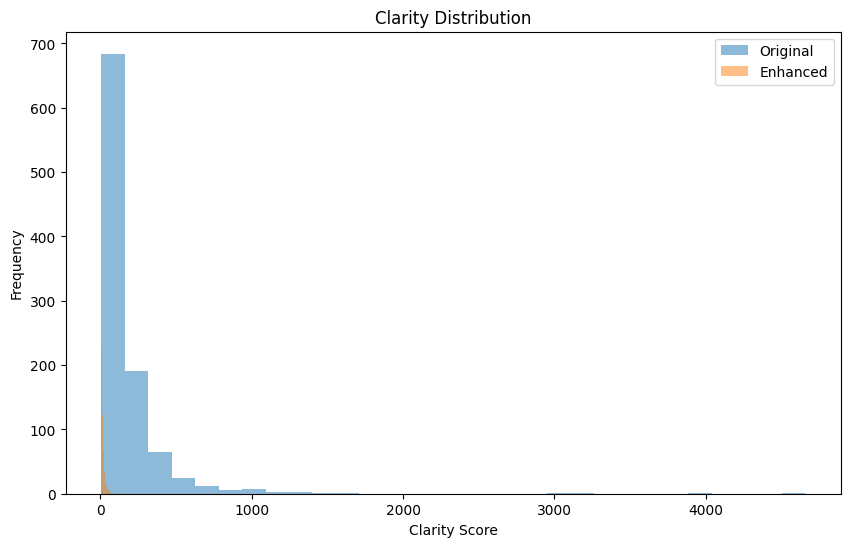

In [70]:
plt.figure(figsize=(10,6))

plt.hist(

    results_df["Original_Clarity"],

    bins=30,

    alpha=0.5,

    label="Original"

)

plt.hist(

    results_df["Enhanced_Clarity"],

    bins=30,

    alpha=0.5,

    label="Enhanced"

)

plt.xlabel("Clarity Score")

plt.ylabel("Frequency")

plt.legend()

plt.title(
    "Clarity Distribution"
)

plt.savefig(
    "Figure_3_Clarity_Distribution.png",
    dpi=300
)

plt.show()

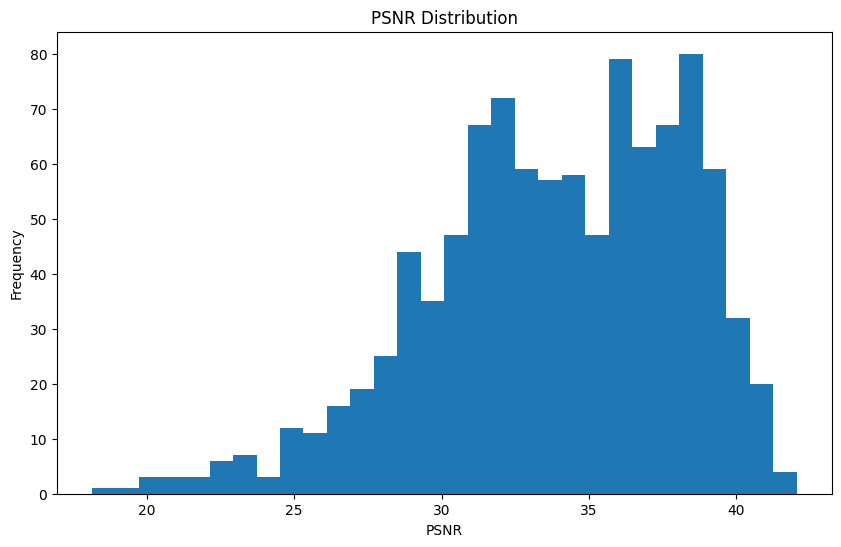

In [71]:
plt.figure(figsize=(10,6))

plt.hist(

    results_df["PSNR"],

    bins=30

)

plt.xlabel("PSNR")

plt.ylabel("Frequency")

plt.title(
    "PSNR Distribution"
)

plt.savefig(
    "Figure_4_PSNR.png",
    dpi=300
)

plt.show()

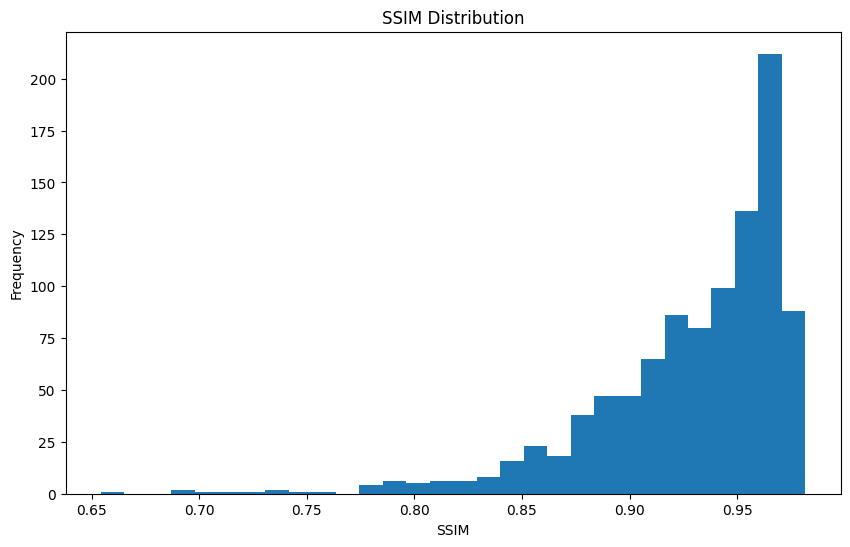

In [72]:
plt.figure(figsize=(10,6))

plt.hist(

    results_df["SSIM"],

    bins=30

)

plt.xlabel("SSIM")

plt.ylabel("Frequency")

plt.title(
    "SSIM Distribution"
)

plt.savefig(
    "Figure_5_SSIM.png",
    dpi=300
)

plt.show()

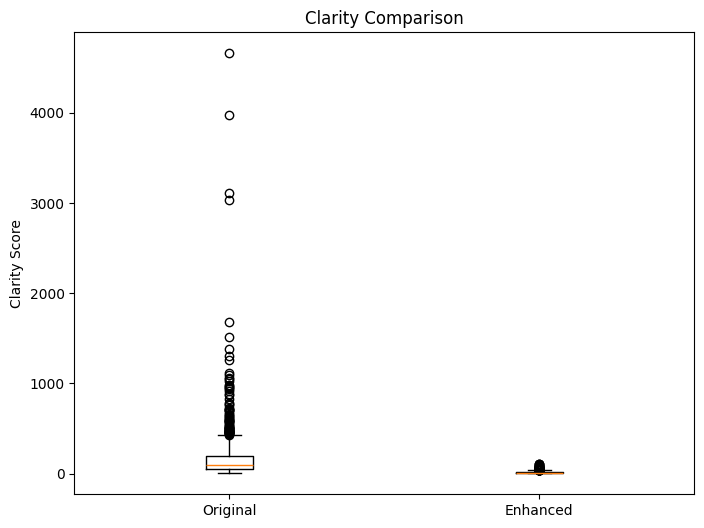

In [73]:
plt.figure(figsize=(8,6))

plt.boxplot([

    results_df["Original_Clarity"],

    results_df["Enhanced_Clarity"]

])

plt.xticks(

    [1,2],

    ["Original","Enhanced"]

)

plt.ylabel(
    "Clarity Score"
)

plt.title(
    "Clarity Comparison"
)

plt.savefig(
    "Figure_6_Boxplot.png",
    dpi=300
)

plt.show()

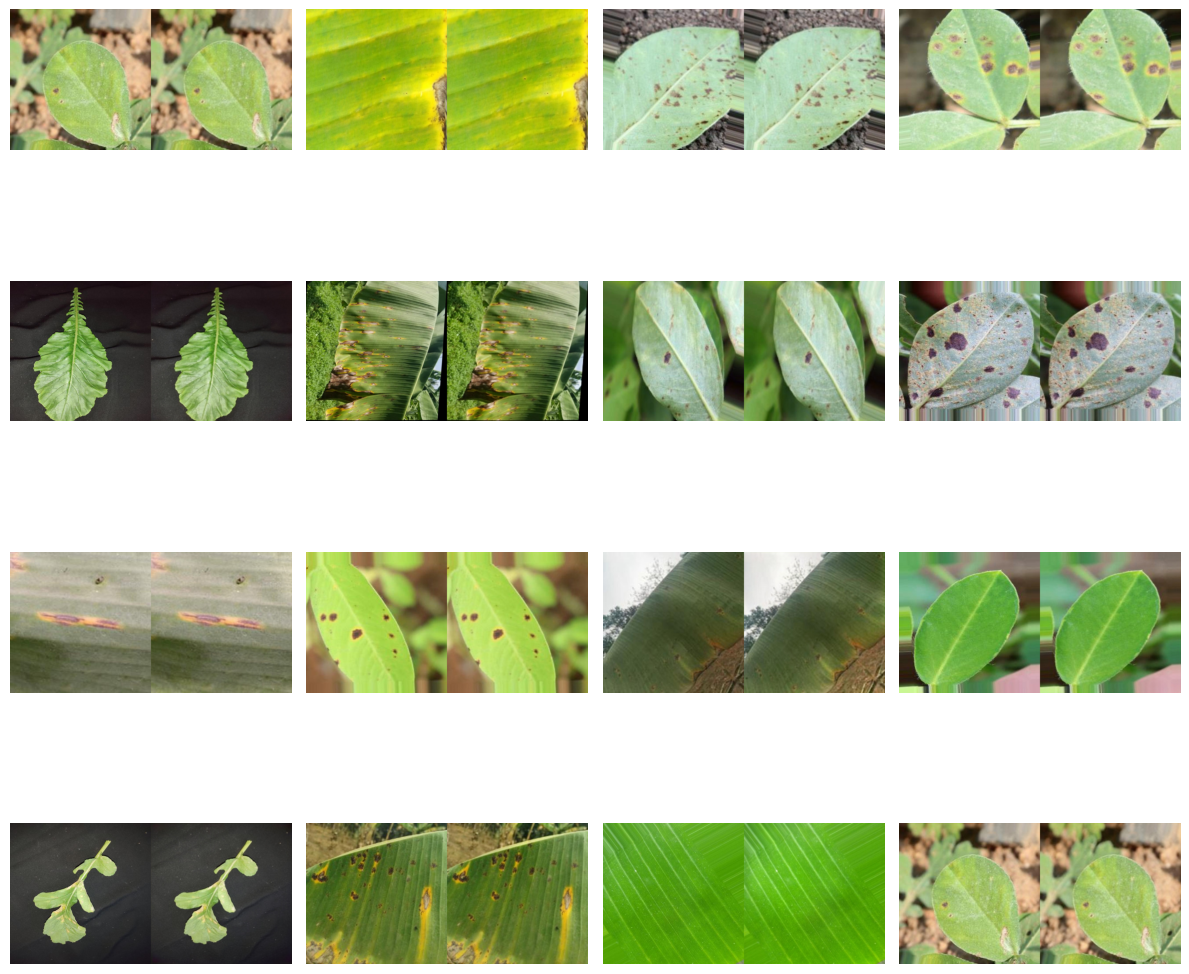

In [74]:
fig, axes = plt.subplots(
    4,
    4,
    figsize=(12,12)
)

for ax in axes.ravel():

    idx = random.randint(
        0,
        len(orig_sample)-1
    )

    orig = cv2.imread(
        orig_sample[idx]
    )

    enh = cv2.imread(
        enh_sample[idx]
    )

    combined = np.hstack([

        cv2.cvtColor(
            orig,
            cv2.COLOR_BGR2RGB
        ),

        cv2.cvtColor(
            enh,
            cv2.COLOR_BGR2RGB
        )

    ])

    ax.imshow(combined)

    ax.axis("off")

plt.tight_layout()

plt.savefig(
    "Figure_2_Visual_Comparisons.png",
    dpi=300
)

plt.show()

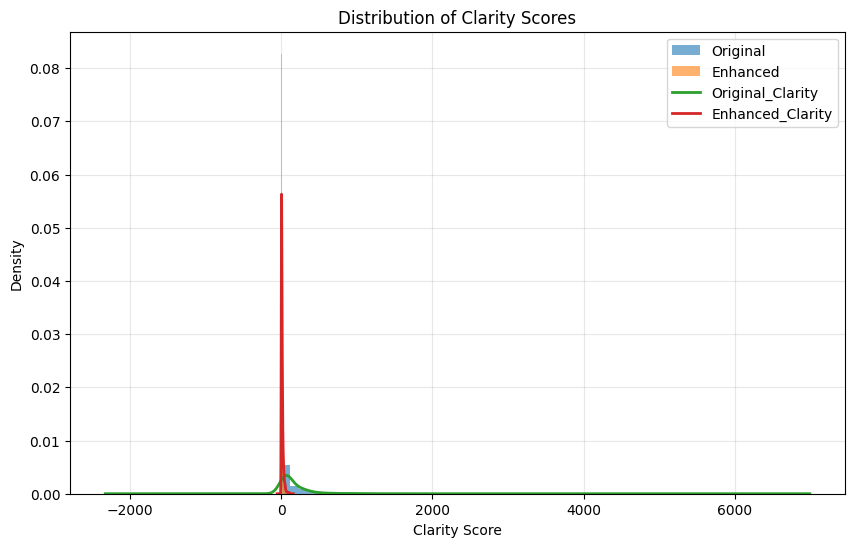

In [75]:
plt.figure(figsize=(10,6))

plt.hist(results_df["Original_Clarity"],
         bins=40,
         alpha=0.6,
         density=True,
         label="Original")

plt.hist(results_df["Enhanced_Clarity"],
         bins=40,
         alpha=0.6,
         density=True,
         label="Enhanced")

results_df["Original_Clarity"].plot(
    kind="density",
    linewidth=2
)

results_df["Enhanced_Clarity"].plot(
    kind="density",
    linewidth=2
)

plt.xlabel("Clarity Score")
plt.ylabel("Density")
plt.title("Distribution of Clarity Scores")
plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig(
    "Figure_3_Clarity_Distribution.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

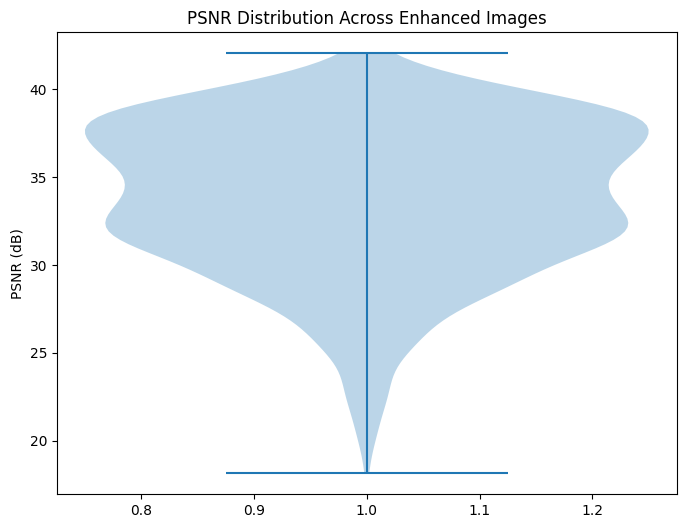

In [76]:
plt.figure(figsize=(8,6))

plt.violinplot(
    results_df["PSNR"]
)

plt.ylabel("PSNR (dB)")
plt.title("PSNR Distribution Across Enhanced Images")

plt.savefig(
    "Figure_4_PSNR_Violin.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

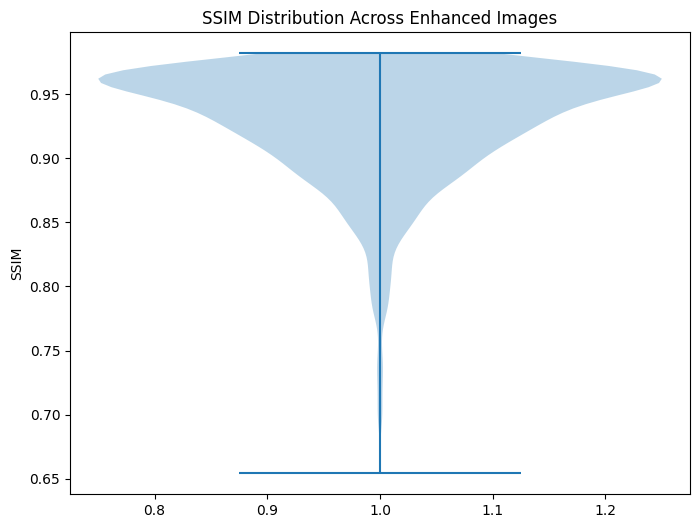

In [77]:
plt.figure(figsize=(8,6))

plt.violinplot(
    results_df["SSIM"]
)

plt.ylabel("SSIM")
plt.title("SSIM Distribution Across Enhanced Images")

plt.savefig(
    "Figure_5_SSIM_Violin.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

C:\Users\admin\AppData\Local\Temp\ipykernel_24104\4204975870.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


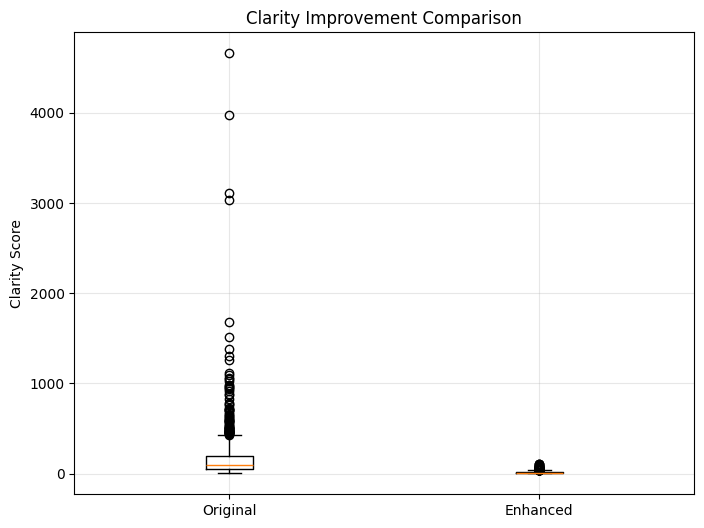

In [78]:
plt.figure(figsize=(8,6))

plt.boxplot(
    [
        results_df["Original_Clarity"],
        results_df["Enhanced_Clarity"]
    ],
    labels=[
        "Original",
        "Enhanced"
    ]
)

plt.ylabel("Clarity Score")

plt.title(
    "Clarity Improvement Comparison"
)

plt.grid(True, alpha=0.3)

plt.savefig(
    "Figure_6_Clarity_Boxplot.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

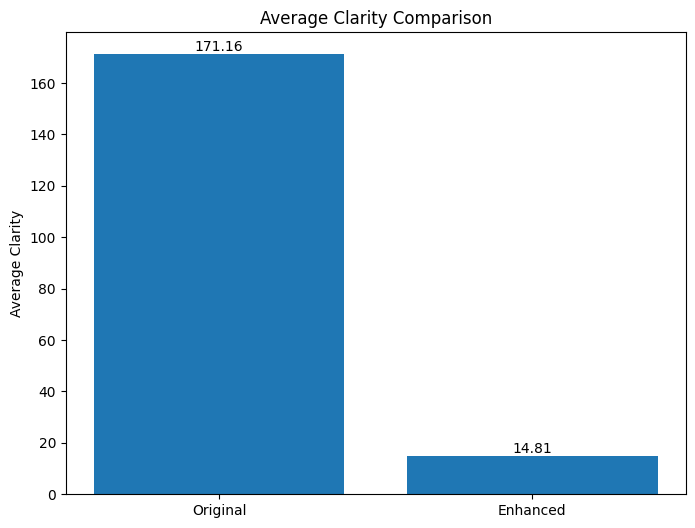

In [79]:
metrics = [
    mean_orig,
    mean_enh
]

labels = [
    "Original",
    "Enhanced"
]

plt.figure(figsize=(8,6))

bars = plt.bar(
    labels,
    metrics
)

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"{height:.2f}",
        ha="center",
        va="bottom"
    )

plt.ylabel("Average Clarity")

plt.title(
    "Average Clarity Comparison"
)

plt.savefig(
    "Figure_7_Average_Clarity.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

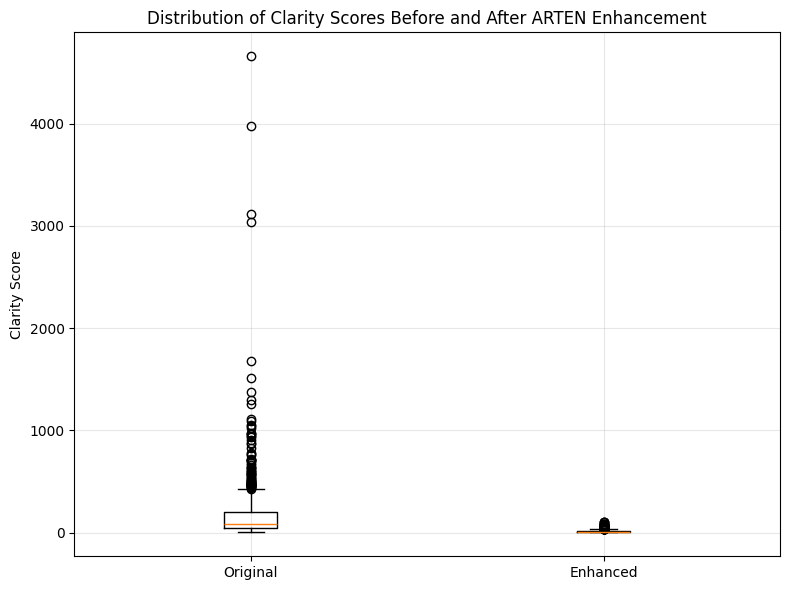

In [80]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.boxplot(
    [
        results_df["Original_Clarity"],
        results_df["Enhanced_Clarity"]
    ],
    tick_labels=[
        "Original",
        "Enhanced"
    ]
)

plt.ylabel("Clarity Score")

plt.title(
    "Distribution of Clarity Scores Before and After ARTEN Enhancement"
)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "Figure_Clarity_Boxplot.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

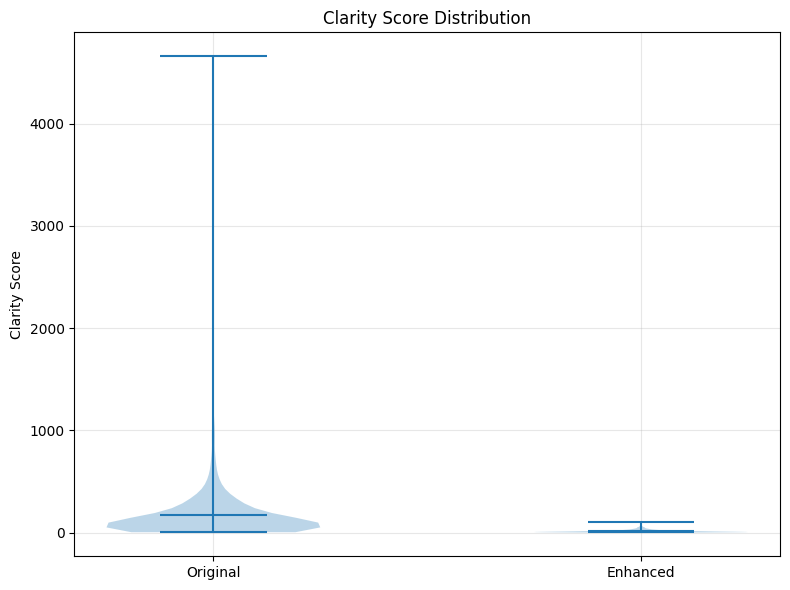

In [81]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.violinplot(
    [
        results_df["Original_Clarity"],
        results_df["Enhanced_Clarity"]
    ],
    showmeans=True
)

plt.xticks(
    [1,2],
    ["Original","Enhanced"]
)

plt.ylabel("Clarity Score")

plt.title(
    "Clarity Score Distribution"
)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "Figure_Clarity_Violin.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()